# C5: Model Tuning (Hyperparameter Optimization)

## 1. Introduction

In machine learning, there are two types of parameters:

1.  **Model Parameters**: Learned from the data during training (e.g., weights in linear regression, split points in a decision tree).
2.  **Hyperparameters**: Set *before* training to control the learning process (e.g., `max_depth` in a tree, `learning_rate` in boosting).

**Model Tuning** (or Hyperparameter Optimization) is the process of finding the optimal set of hyperparameters to maximize model performance and prevent overfitting.

### Hyperparameter Tuning Workflow:

1. **Define Model & Hyperparameter Space** - Select the model and specify the range of hyperparameters to tune.
2. **Choose Tuning Strategy** - Grid Search, Random Search, or Bayesian Optimization.
3. **Cross-Validation** - Use K-Fold CV to evaluate each configuration robustly.
4. **Train & Evaluate** - For each hyperparameter combination, train and measure performance.
5. **Select Best Model** - Choose the configuration with the best validation performance.
6. **Final Evaluation** - Test on unseen data to verify generalization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_curve, auc, roc_auc_score
from sklearn.datasets import load_breast_cancer
from scipy.stats import randint

np.random.seed(42)
print("Libraries imported.")

Libraries imported.


## 2. Cross-Validation

Evaluating a model on a single test set can be misleading if that specific split happens to be easy or hard. **K-Fold Cross-Validation** provides a more robust estimate of performance.

1.  Split data into **K** folds (e.g., 5 or 10).
2.  Train on **K-1** folds, validate on the remaining **1** fold.
3.  Repeat **K** times, so every fold serves as the validation set once.
4.  Average the scores.

![K-Fold Cross Validation](https://scikit-learn.org/stable/_images/grid_search_cross_validation.png)
*(Source: scikit-learn documentation)*

In [2]:
# Load Dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Before Tuning: Default Decision Tree

In [3]:
# Default Decision Tree (before tuning)
clf_default = DecisionTreeClassifier(random_state=42)
clf_default.fit(X_train, y_train)

# Predictions
y_pred_default = clf_default.predict(X_test)
y_pred_proba_default = clf_default.predict_proba(X_test)[:, 1]

# Metrics
acc_default = accuracy_score(y_test, y_pred_default)
auc_default = roc_auc_score(y_test, y_pred_proba_default)

print(f"Default Model - Test Accuracy: {acc_default:.4f}")
print(f"Default Model - AUC: {auc_default:.4f}")

Default Model - Test Accuracy: 0.9474
Default Model - AUC: 0.9440


### After Cross-Validation: Tuned with Manual Parameter Selection

In [4]:
# Perform 5-Fold Cross-Validation on Default Model
scores = cross_val_score(clf_default, X_train, y_train, cv=5)
print(f"Cross-Validation Scores: {scores}")
print(f"Mean CV Accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

# Based on CV, manually select better hyperparameters
clf_tuned_cv = DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=42)
clf_tuned_cv.fit(X_train, y_train)

# Predictions
y_pred_tuned_cv = clf_tuned_cv.predict(X_test)
y_pred_proba_tuned_cv = clf_tuned_cv.predict_proba(X_test)[:, 1]

# Metrics
acc_tuned_cv = accuracy_score(y_test, y_pred_tuned_cv)
auc_tuned_cv = roc_auc_score(y_test, y_pred_proba_tuned_cv)

print(f"\nTuned Model (After CV) - Test Accuracy: {acc_tuned_cv:.4f}")
print(f"Tuned Model (After CV) - AUC: {auc_tuned_cv:.4f}")

Cross-Validation Scores: [0.92307692 0.89010989 0.93406593 0.9010989  0.93406593]
Mean CV Accuracy: 0.9165 (+/- 0.0179)

Tuned Model (After CV) - Test Accuracy: 0.9474
Tuned Model (After CV) - AUC: 0.9355


### ROC Curve Comparison: Before vs After Cross-Validation

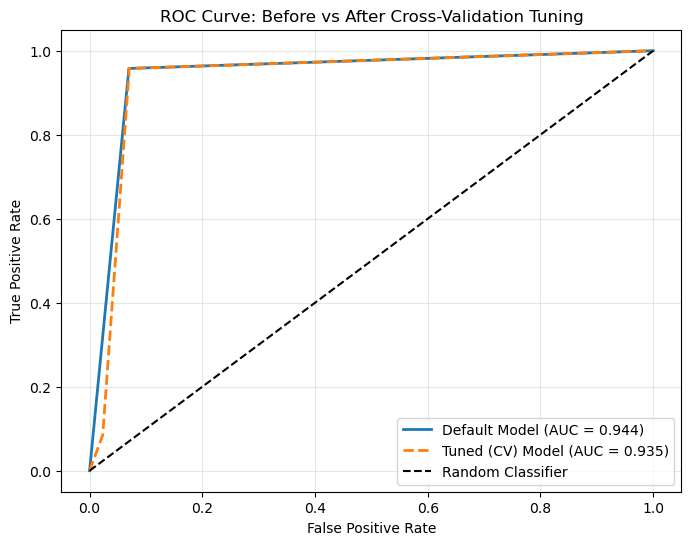

In [5]:
# ROC Curves
fpr_default, tpr_default, _ = roc_curve(y_test, y_pred_proba_default)
fpr_tuned_cv, tpr_tuned_cv, _ = roc_curve(y_test, y_pred_proba_tuned_cv)

plt.figure(figsize=(8, 6))
plt.plot(fpr_default, tpr_default, label=f'Default Model (AUC = {auc_default:.3f})', linewidth=2)
plt.plot(fpr_tuned_cv, tpr_tuned_cv, label=f'Tuned (CV) Model (AUC = {auc_tuned_cv:.3f})', linewidth=2, linestyle='--')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Before vs After Cross-Validation Tuning')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3. GridSearchCV

**Grid Search** is an exhaustive search through a manually specified subset of the hyperparameter space. It evaluates all possible combinations.

-   **Pros**: Guaranteed to find the best combination within your grid.
-   **Cons**: Computationally expensive as the number of parameters grows.

![Grid vs Random Search](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fmiro.medium.com%2Fmax%2F1838%2F1*ZTlQm_WRcrNqL-nLnx6GJA.png&f=1&nofb=1&ipt=d9b3c3a2e1f0e7c4d5b8e9f0e1d2c3a4b5c6d7e8f9a0b1c2d3e4f5a6b7c8d9e0)
*(Source: Medium - Grid Search vs Random Search Comparison)*

In [6]:
# Define Parameter Grid
param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'criterion': ['gini', 'entropy']
}

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

# Fit
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV Score: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 10}
Best CV Score: 0.9473


### After GridSearchCV: Best Model Evaluation

In [7]:
# Best Model from GridSearch
clf_grid = grid_search.best_estimator_

# Predictions
y_pred_grid = clf_grid.predict(X_test)
y_pred_proba_grid = clf_grid.predict_proba(X_test)[:, 1]

# Metrics
acc_grid = accuracy_score(y_test, y_pred_grid)
auc_grid = roc_auc_score(y_test, y_pred_proba_grid)

print(f"GridSearch Model - Test Accuracy: {acc_grid:.4f}")
print(f"GridSearch Model - AUC: {auc_grid:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_grid))

GridSearch Model - Test Accuracy: 0.9561
GridSearch Model - AUC: 0.9443

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.91      0.94        43
           1       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



### ROC Curve Comparison: Before vs After GridSearchCV

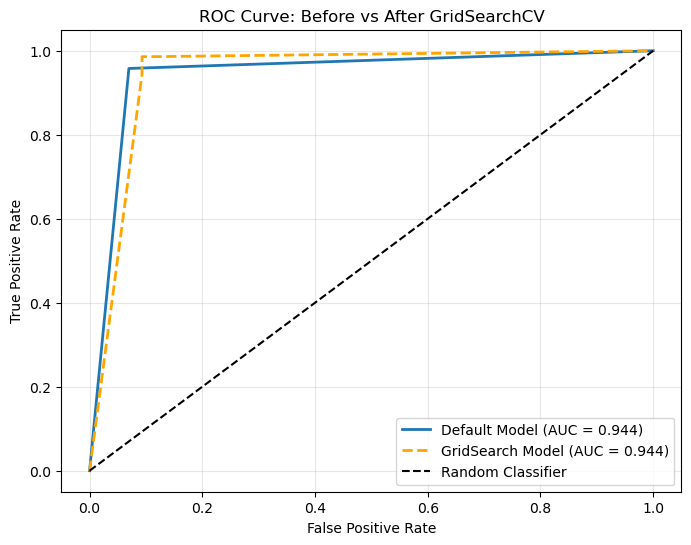

In [8]:
# ROC Curves
fpr_grid, tpr_grid, _ = roc_curve(y_test, y_pred_proba_grid)

plt.figure(figsize=(8, 6))
plt.plot(fpr_default, tpr_default, label=f'Default Model (AUC = {auc_default:.3f})', linewidth=2)
plt.plot(fpr_grid, tpr_grid, label=f'GridSearch Model (AUC = {auc_grid:.3f})', linewidth=2, linestyle='--', color='orange')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Before vs After GridSearchCV')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. RandomizedSearchCV

**Randomized Search** samples a fixed number of configurations from specified distributions. It doesn't try every combination, but it's much faster and often finds a very good solution.

-   **Pros**: Faster, explores a wider range of values.
-   **Cons**: No guarantee of finding the absolute best combination.

In [9]:
# Define Parameter Distributions
param_dist = {
    'n_estimators': randint(50, 200),
    'max_depth': [3, 5, 10, None],
    'min_samples_leaf': randint(1, 10)
}

# Initialize RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Fit
random_search.fit(X_train, y_train)

print(f"Best Parameters: {random_search.best_params_}")
print(f"Best CV Score: {random_search.best_score_:.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 124}
Best CV Score: 0.9560


### Before Tuning: Default Random Forest

In [10]:
# Default Random Forest (before tuning)
rf_default = RandomForestClassifier(random_state=42)
rf_default.fit(X_train, y_train)

# Predictions
y_pred_rf_default = rf_default.predict(X_test)
y_pred_proba_rf_default = rf_default.predict_proba(X_test)[:, 1]

# Metrics
acc_rf_default = accuracy_score(y_test, y_pred_rf_default)
auc_rf_default = roc_auc_score(y_test, y_pred_proba_rf_default)

print(f"Default Random Forest - Test Accuracy: {acc_rf_default:.4f}")
print(f"Default Random Forest - AUC: {auc_rf_default:.4f}")

Default Random Forest - Test Accuracy: 0.9649
Default Random Forest - AUC: 0.9953


### After RandomizedSearchCV: Best Model Evaluation

In [11]:
# Best Model from RandomizedSearch
rf_random = random_search.best_estimator_

# Predictions
y_pred_random = rf_random.predict(X_test)
y_pred_proba_random = rf_random.predict_proba(X_test)[:, 1]

# Metrics
acc_random = accuracy_score(y_test, y_pred_random)
auc_random = roc_auc_score(y_test, y_pred_proba_random)

print(f"RandomizedSearch Model - Test Accuracy: {acc_random:.4f}")
print(f"RandomizedSearch Model - AUC: {auc_random:.4f}")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_random))

RandomizedSearch Model - Test Accuracy: 0.9649
RandomizedSearch Model - AUC: 0.9964

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.95        43
           1       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



### ROC Curve Comparison: Before vs After RandomizedSearchCV

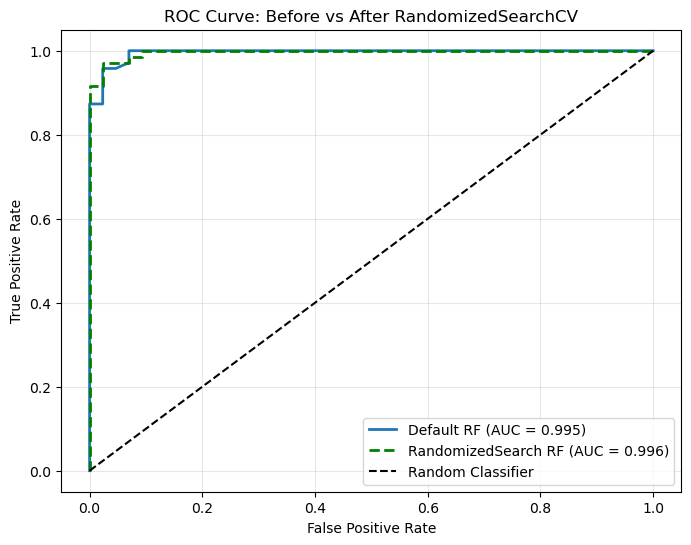

In [12]:
# ROC Curves
fpr_rf_default, tpr_rf_default, _ = roc_curve(y_test, y_pred_proba_rf_default)
fpr_random, tpr_random, _ = roc_curve(y_test, y_pred_proba_random)

plt.figure(figsize=(8, 6))
plt.plot(fpr_rf_default, tpr_rf_default, label=f'Default RF (AUC = {auc_rf_default:.3f})', linewidth=2)
plt.plot(fpr_random, tpr_random, label=f'RandomizedSearch RF (AUC = {auc_random:.3f})', linewidth=2, linestyle='--', color='green')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Before vs After RandomizedSearchCV')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Overall Performance Comparison

             Model  Accuracy       AUC
0       Default DT  0.947368  0.943990
1    Tuned DT (CV)  0.947368  0.935473
2    GridSearch DT  0.956140  0.944317
3       Default RF  0.964912  0.995251
4  RandomSearch RF  0.964912  0.996397


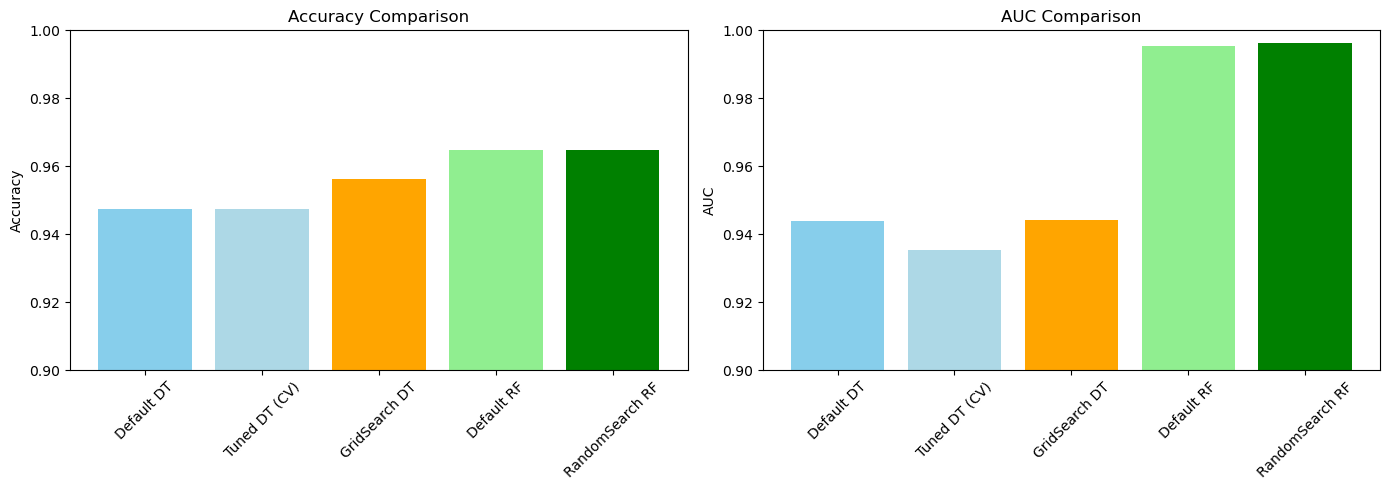

In [13]:
# Summary of All Models
results = pd.DataFrame({
    'Model': ['Default DT', 'Tuned DT (CV)', 'GridSearch DT', 'Default RF', 'RandomSearch RF'],
    'Accuracy': [acc_default, acc_tuned_cv, acc_grid, acc_rf_default, acc_random],
    'AUC': [auc_default, auc_tuned_cv, auc_grid, auc_rf_default, auc_random]
})

print(results)

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Comparison
axes[0].bar(results['Model'], results['Accuracy'], color=['skyblue', 'lightblue', 'orange', 'lightgreen', 'green'])
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy Comparison')
axes[0].set_ylim(0.9, 1.0)
axes[0].tick_params(axis='x', rotation=45)

# AUC Comparison
axes[1].bar(results['Model'], results['AUC'], color=['skyblue', 'lightblue', 'orange', 'lightgreen', 'green'])
axes[1].set_ylabel('AUC')
axes[1].set_title('AUC Comparison')
axes[1].set_ylim(0.9, 1.0)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 6. Exercise

1.  Initialize a `GradientBoostingClassifier`.
2.  Create a parameter grid for `n_estimators` (e.g., [50, 100]), `learning_rate` (e.g., [0.01, 0.1]), and `max_depth` (e.g., [3, 5]).
3.  Use `GridSearchCV` to find the best parameters.
4.  Print the best parameters, test accuracy, and plot the ROC curve comparing default vs tuned models.

In [ ]:
# TODO: Create GradientBoostingClassifier, Param Grid, and Run GridSearchCV
# TODO: Compare Default vs Tuned with ROC curves

# Hint: See the Solutions folder for the complete solution